Santiago Baeza

# Reducción de varianza en opciones asiáticas

# Clase 18 - 14/10/2026

In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.stats import gmean

# Opción cuadrática geométrica para un call asiático

In [15]:
S0 = 100
K = 100
sigma = 0.20
r = 0.05
T = 1

In [ ]:
def precio_call_asiatico_geometrico(S0, K, r, sigma, T):
    # Volatilidad ajustada para el promedio geométrico continuo 
    sigmaA = sigma / np.sqrt(3.0)
    v_sq = (sigmaA**2) * T  # Varianza total ajustada 
    v = sigmaA * np.sqrt(T) # Desviación estándar total 
    
    # Parámetro de tendencia o costo de acarreo ajustado 
    bA = 0.5 * (r - 0.5 * sigma**2)  # Es la tasa de crecimiento esperada bajo la medida neutral al riesgo
    
    # Media ajustada del logaritmo del precio promedio 
    m = np.log(S0) + bA * T
    
    d1 = (m + v_sq - np.log(K)) / v
    d2 = d1 - v
    
    precio = np.exp(-r * T) * (np.exp(m + 0.5 * v_sq) * norm.cdf(d1) - K * norm.cdf(d2))
    
    print(f"sigmaA (Volatilidad ajustada): {sigmaA:.4f}")
    print(f"bA (Tendencia/costo de acarreo): {bA:.4f}")
    print(f"d1: {d1:.4f}")
    print(f"d2: {d2:.4f}")
    
    return precio

In [17]:
resultado = precio_call_asiatico_geometrico(S0, K, r, sigma, T)
print(f"Precio del Call Asiático Geométrico: {resultado:.4f}")

sigmaA (Volatilidad ajustada): 0.1155
bA (Tendencia/costo de acarreo): 0.0150
d1: 0.2454
d2: 0.1299
Precio del Call Asiático Geométrico: 5.5468


# Media aritmética y media geométrica

In [6]:
S0 = 100.0      
K = 100.0       
r = 0.05        
sigma = 0.20    
T = 1.0        
M = 100          # Número de rutas
n = 252         # Número de pasos diarios
dt = T / n      # Tamaño del paso

In [ ]:
sigmaA = sigma / np.sqrt(3.0)       # Volatilidad ajustada
v_sq = (sigmaA**2) * T              # Varianza total ajustada
v = sigmaA * np.sqrt(T)             # Desviación estándar total
bA = 0.5 * (r - 0.5 * sigma**2)     # Tendencia / costo de acarreo ajustado
m = np.log(S0) + bA * T             # Media ajustada

np.random.seed(42)

# Simulación de las rutas
paths = np.zeros((n + 1, M))
paths[0] = S0

for t_i in range(1, n + 1):
    z = np.random.standard_normal(M)
    paths[t_i] = paths[t_i - 1] * np.exp((r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * z)

medias_aritmeticas = np.mean(paths, axis=0)
medias_geometricas = gmean(paths, axis=0)

payoffs_call_arit = np.maximum(medias_aritmeticas - K, 0)
payoffs_call_geom = np.maximum(medias_geometricas - K, 0)

payoffs_put_arit = np.maximum(K - medias_aritmeticas, 0)
payoffs_put_geom = np.maximum(K - medias_geometricas, 0)

precio_call_aritmetico = np.exp(-r * T) * np.mean(payoffs_call_arit)
precio_call_geometrico = np.exp(-r * T) * np.mean(payoffs_call_geom)

precio_put_aritmetico = np.exp(-r * T) * np.mean(payoffs_put_arit)
precio_put_geometrico = np.exp(-r * T) * np.mean(payoffs_put_geom)

print(" Resultados Individuales por Ruta (M = 100, n = 252) ")
for i in range(M):
    print(f"Ruta {i+1:2d} -> Media Arit.: {medias_aritmeticas[i]:7.2f} | Media Geom. (gmean): {medias_geometricas[i]:7.2f}")

print(f"Precio Call Asiático Aritmético:  {precio_call_aritmetico:.4f}")
print(f"Precio Call Asiático Geométrico:  {precio_call_geometrico:.4f}")
print(f"Precio Put Asiático Aritmético:   {precio_put_aritmetico:.4f}")
print(f"Precio Put Asiático Geométrico:   {precio_put_geometrico:.4f}")

 Resultados Individuales por Ruta (M = 100, n = 252) 
Ruta  1 -> Media Arit.:  104.68 | Media Geom. (gmean):  104.51
Ruta  2 -> Media Arit.:   84.48 | Media Geom. (gmean):   84.02
Ruta  3 -> Media Arit.:  103.42 | Media Geom. (gmean):  103.33
Ruta  4 -> Media Arit.:  110.26 | Media Geom. (gmean):  110.04
Ruta  5 -> Media Arit.:   96.06 | Media Geom. (gmean):   95.95
Ruta  6 -> Media Arit.:   88.03 | Media Geom. (gmean):   87.60
Ruta  7 -> Media Arit.:  103.37 | Media Geom. (gmean):  103.14
Ruta  8 -> Media Arit.:   95.87 | Media Geom. (gmean):   95.62
Ruta  9 -> Media Arit.:  102.78 | Media Geom. (gmean):  102.66
Ruta 10 -> Media Arit.:  130.48 | Media Geom. (gmean):  130.03
Ruta 11 -> Media Arit.:  103.48 | Media Geom. (gmean):  103.29
Ruta 12 -> Media Arit.:  116.64 | Media Geom. (gmean):  116.13
Ruta 13 -> Media Arit.:  113.33 | Media Geom. (gmean):  113.14
Ruta 14 -> Media Arit.:   83.50 | Media Geom. (gmean):   82.81
Ruta 15 -> Media Arit.:  110.96 | Media Geom. (gmean):  110.75
R

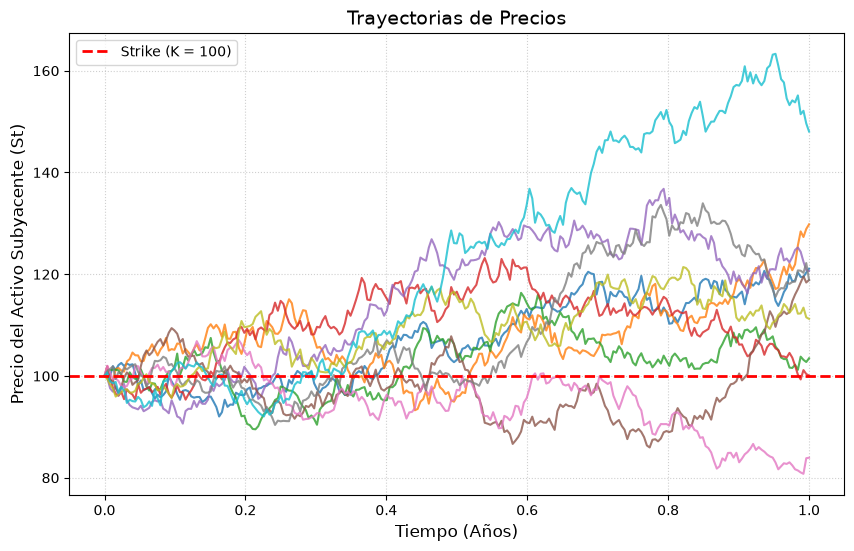

In [18]:
t_grid = np.linspace(0, T, n + 1) # Eje temporal de 0 a 1 año (252 pasos)

plt.figure(figsize=(10, 6))
plt.plot(t_grid, paths, alpha=0.8)
plt.axhline(y=K, color='red', linestyle='--', linewidth=2, label=f'Strike (K = {K})')

plt.title('Trayectorias de Precios', fontsize=14)
plt.xlabel('Tiempo (Años)', fontsize=12)
plt.ylabel('Precio del Activo Subyacente (St)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

# E[x], var(y), E(y), E(Y), var(Y)

In [ ]:
# E(X) 
sigmaA = sigma / np.sqrt(3.0)
v_sq = (sigmaA**2) * T
v = sigmaA * np.sqrt(T)
bA = 0.5 * (r - 0.5 * sigma**2)
m = np.log(S0) + bA * T
d1 = (m + v_sq - np.log(K)) / v
d2 = d1 - v
E_X = np.exp(-r * T) * (np.exp(m + 0.5 * v_sq) * norm.cdf(d1) - K * norm.cdf(d2))

# var(y) 
yprom = np.mean(y)
var_y = np.sum((y - yprom)**2) / (M - 1)

# E(y)
E_y = yprom

# b estimado 
xprom = np.mean(x)
var_X = np.sum((x - xprom)**2) / (M - 1)
num_b = np.sum((x - xprom) * (y - yprom))
b = num_b / np.sum((x - xprom)**2)

# E(Y) ajustado 
E_Y = yprom - b * (xprom - E_X)

# var(Y) ajustada 
sigmax = np.std(x, ddof=1)
sigmay = np.std(y, ddof=1)
pxy = np.corrcoef(x, y)[0, 1]
var_Y = var_y + (b**2) * var_X - 2 * b * sigmax * sigmay * pxy

print(f"E(X) {E_X:.4f}")
print(f"var(y): {var_y:.4f}")
print(f"E(y): {E_y:.4f}")
print(f"E(Y): {E_Y:.4f}")
print(f"var(Y): {var_Y:.4f}")

E(X) 5.5468
var(y): 48.3385
E(y): 8.4338
E(Y): 5.8094
var(Y): 0.0862
